# Imports

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
from scipy import ndimage
from skimage import filters, measure, morphology

# Slike so v mapi vaje 09 (deluje iz 10_vaje/ in iz 10_vaje/resitve/)
GRADIVO = Path("../09_vaje/navodila/Gradivo")
if not GRADIVO.exists():
    GRADIVO = Path("../../09_vaje/navodila/Gradivo")

# Funkcije

In [2]:
def zgladi(img, sigma):
    """Gaussovo glajenje; vrne float sliko v intervalu [0, 1]."""
    return filters.gaussian(img, sigma=sigma) if sigma > 0 else img / 255.0


def prag(img_f, razredi=2):
    """Otsujev prag (razredi = 2) ali spodnji prag Otsujeve metode s tremi razredi (razredi = 3)."""
    if razredi == 2:
        return filters.threshold_otsu(img_f)
    return filters.threshold_multiotsu(img_f, classes=razredi)[0]


def maska_otsu(img_f, razredi=2):
    """Temni objekti: piksli pod pragom."""
    return img_f < prag(img_f, razredi)


def element_disk(r):
    """Strukturni element: disk s polmerom r (bool array (2r+1) x (2r+1))."""
    y, x = np.mgrid[-r:r + 1, -r:r + 1]
    return x**2 + y**2 <= r**2


def dilatacija(M, E):
    """Binarna dilatacija: piksel je 1, če element, postavljen vanj, prekrije vsaj en piksel maske."""
    r = E.shape[0] // 2
    H, W = M.shape
    P = np.pad(M, r)
    out = np.zeros_like(M)
    for di, dj in zip(*np.nonzero(E)):
        out |= P[di:di + H, dj:dj + W]
    return out


def erozija(M, E):
    """Binarna erozija: piksel ostane 1, če element, postavljen vanj, v celoti leži v maski."""
    r = E.shape[0] // 2
    H, W = M.shape
    P = np.pad(M, r, constant_values=True)   # zunaj slike privzamemo ospredje
    out = np.ones_like(M)
    for di, dj in zip(*np.nonzero(E)):
        out &= P[di:di + H, dj:dj + W]
    return out


def odpiranje(M, E):
    return dilatacija(erozija(M, E), E)


def zapiranje(M, E):
    return erozija(dilatacija(M, E), E)


def segmentiraj(img, sigma=5, r=3, A_min=100, razredi=3):
    """Celoten postopek: glajenje, prag, zapolnitev lukenj, odpiranje, označevanje, odstranitev majhnih.
    Vrne (oznake, seznam regij)."""
    M = maska_otsu(zgladi(img, sigma), razredi)
    M = ndimage.binary_fill_holes(M)
    M = odpiranje(M, element_disk(r))
    L = measure.label(M, connectivity=2)
    ohrani = [reg.label for reg in measure.regionprops(L) if reg.area >= A_min]
    L = measure.label(np.isin(L, ohrani), connectivity=2)
    return L, measure.regionprops(L)


def okroglost(reg):
    """Okroglost 4 pi A / P^2 (1 za krog)."""
    return 4 * np.pi * reg.area / reg.perimeter**2

# Testno območje

In [3]:
img = cv2.imread(str(GRADIVO / "Kontrola.tif"), cv2.IMREAD_UNCHANGED)
print(img.shape, img.dtype, img.min(), img.max())

# P2: erozija in dilatacija majhnega kvadrata s križem 3 x 3
M = np.zeros((7, 7), bool)
M[2:5, 2:5] = True
kriz = element_disk(1)
print(kriz.astype(int))
print("dilatacija:", dilatacija(M, kriz).sum(), " erozija:", erozija(M, kriz).sum())
print("skimage:   ", morphology.binary_dilation(M, kriz).sum(), morphology.binary_erosion(M, kriz).sum())

# P4: okroglost kroga in kvadrata
print("krog r=20:", okroglost(measure.regionprops(element_disk(20).astype(int))[0]))

(1026, 1024) uint8 0 255
[[0 1 0]
 [1 1 1]
 [0 1 0]]
dilatacija: 21  erozija: 1
skimage:    21 1
krog r=20: 0.9081810576523069


C:\Users\Rene\AppData\Local\Temp\ipykernel_36636\1119497903.py:10: FutureWarning: `binary_dilation` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.dilation` instead. Note the lack of mirroring for non-symmetric footprints (see docstring notes).
  print("skimage:   ", morphology.binary_dilation(M, kriz).sum(), morphology.binary_erosion(M, kriz).sum())
C:\Users\Rene\AppData\Local\Temp\ipykernel_36636\1119497903.py:10: FutureWarning: `binary_erosion` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.erosion` instead. Note the pixel shift by 1 for even-sized footprints (see docstring notes).
  print("skimage:   ", morphology.binary_dilation(M, kriz).sum(), morphology.binary_erosion(M, kriz).sum())


# Naloga 1 - Slika 2

sigma =  0: prag2 = 121 (7179 območij), prag3 = 92 (7092 območij)


sigma =  2: prag2 = 118 (993 območij), prag3 = 86 (256 območij)


sigma =  5: prag2 = 115 (170 območij), prag3 = 88 (45 območij)


sigma = 10: prag2 = 121 (51 območij), prag3 = 93 (36 območij)


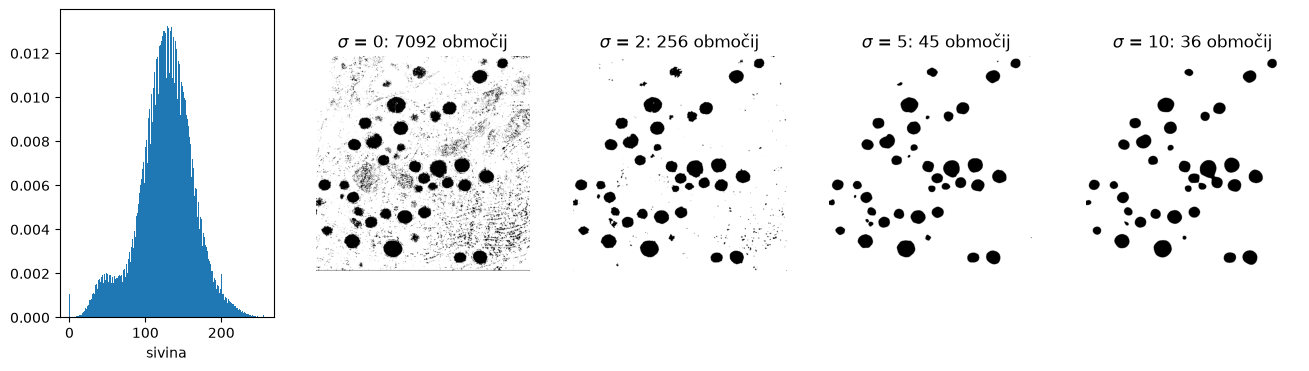

In [4]:
fig = plt.figure(figsize=(16, 4))
ax = fig.add_subplot(1, 5, 1)
ax.hist(img.ravel(), bins=256, range=(0, 256), density=True)
ax.set_xlabel("sivina")
for k, s in enumerate((0, 2, 5, 10)):
    f = zgladi(img, s)
    n = {}
    for raz in (2, 3):
        M = f < prag(f, raz)
        n[raz] = measure.label(M, connectivity=2).max()
    print(f"sigma = {s:2d}: prag2 = {prag(f, 2)*255:.0f} ({n[2]} območij), "
          f"prag3 = {prag(f, 3)*255:.0f} ({n[3]} območij)")
    ax = fig.add_subplot(1, 5, k + 2)
    ax.imshow(M, cmap="gray_r")
    ax.set_title(f"$\\sigma$ = {s}: {n[3]} območij")
    ax.axis("off")
plt.show()

# Naloga 2 - Slika 3

maska     : pikslov =   6697, območij = 22
erozija   : pikslov =   5494, območij = 4
dilatacija: pikslov =   8658, območij = 13
odpiranje : pikslov =   6464, območij = 4
zapiranje : pikslov =   6808, območij = 16
enako skimage: True True


C:\Users\Rene\AppData\Local\Temp\ipykernel_36636\1277017245.py:12: FutureWarning: `binary_erosion` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.erosion` instead. Note the pixel shift by 1 for even-sized footprints (see docstring notes).
  print("enako skimage:", np.array_equal(erozija(izrez, E), morphology.binary_erosion(izrez, E)),
C:\Users\Rene\AppData\Local\Temp\ipykernel_36636\1277017245.py:13: FutureWarning: `binary_dilation` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.dilation` instead. Note the lack of mirroring for non-symmetric footprints (see docstring notes).
  np.array_equal(dilatacija(izrez, E), morphology.binary_dilation(izrez, E)))


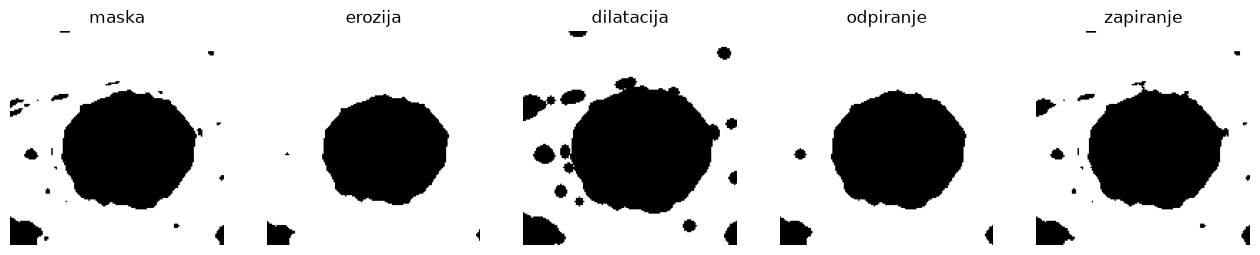

In [5]:
izrez = maska_otsu(zgladi(img, 2))[150:300, 300:450]
E = element_disk(3)
operacije = {"maska": izrez, "erozija": erozija(izrez, E), "dilatacija": dilatacija(izrez, E),
             "odpiranje": odpiranje(izrez, E), "zapiranje": zapiranje(izrez, E)}
fig = plt.figure(figsize=(16, 3.5))
for k, (ime, R) in enumerate(operacije.items()):
    ax = fig.add_subplot(1, 5, k + 1)
    ax.imshow(R, cmap="gray_r")
    ax.set_title(ime)
    ax.axis("off")
    print(f"{ime:10s}: pikslov = {R.sum():6d}, območij = {measure.label(R, connectivity=2).max()}")
print("enako skimage:", np.array_equal(erozija(izrez, E), morphology.binary_erosion(izrez, E)),
      np.array_equal(dilatacija(izrez, E), morphology.binary_dilation(izrez, E)))
plt.show()

# Naloga 3 - Slika 4

dva razreda: 126 objektov, okroglost < 0.5: 17
število objektov: 42


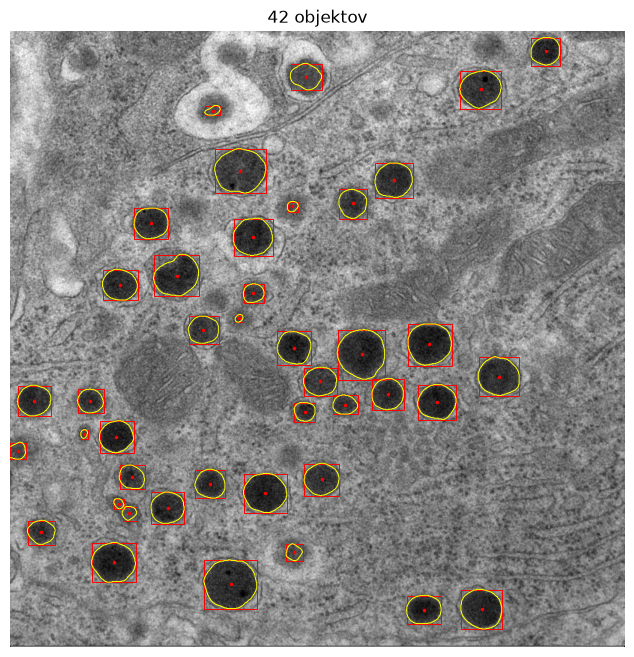

In [6]:
L, regije = segmentiraj(img, sigma=5, r=3, A_min=100)
L2, regije2 = segmentiraj(img, sigma=5, r=3, A_min=100, razredi=2)
print("dva razreda:", len(regije2), "objektov, okroglost < 0.5:", sum(okroglost(r) < 0.5 for r in regije2))
print("število objektov:", len(regije))
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111)
ax.imshow(img, cmap="gray")
ax.contour(L > 0, levels=[0.5], colors="yellow", linewidths=0.7)
for reg in regije:
    y0, x0, y1, x1 = reg.bbox
    ax.add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, color="red", lw=0.7))
    ax.plot(reg.centroid[1], reg.centroid[0], "r.", ms=3)
ax.set_title(f"{len(regije)} objektov")
ax.axis("off")
plt.show()

In [7]:
# Preglednica 3: trije največji objekti
for reg in sorted(regije, key=lambda r: r.area, reverse=True)[:3]:
    print(f"A = {reg.area:5.0f} px, d_ekv = {reg.equivalent_diameter_area:5.1f} px, "
          f"okroglost = {okroglost(reg):.2f}, ekscentričnost = {reg.eccentricity:.2f}, "
          f"težišče = ({reg.centroid[0]:.0f}, {reg.centroid[1]:.0f})")

A =  5527 px, d_ekv =  83.9 px, okroglost = 0.90, ekscentričnost = 0.35, težišče = (920, 367)
A =  5008 px, d_ekv =  79.9 px, okroglost = 0.90, ekscentričnost = 0.28, težišče = (537, 585)
A =  4784 px, d_ekv =  78.0 px, okroglost = 0.89, ekscentričnost = 0.51, težišče = (233, 383)


# Naloga 4 - Slika 5

d_ekv = 48.8 +- 18.4 px, okroglost = 0.91 +- 0.03


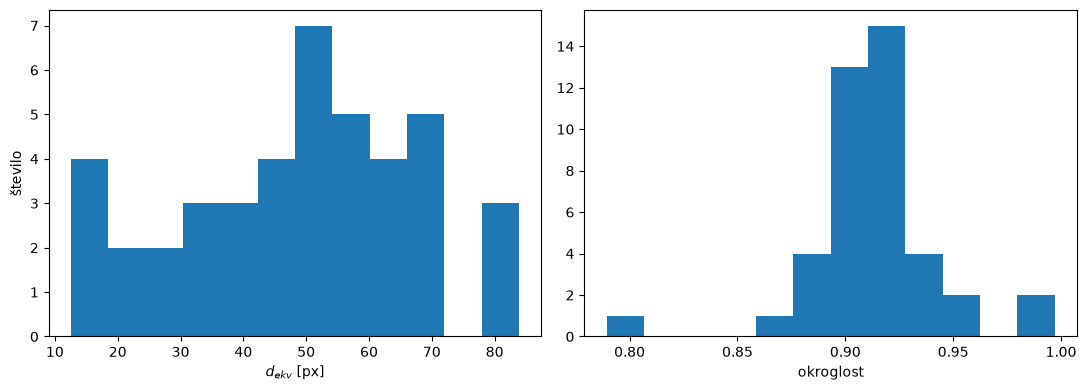

In [8]:
d = np.array([r.equivalent_diameter_area for r in regije])
c = np.array([okroglost(r) for r in regije])
fig = plt.figure(figsize=(11, 4))
ax = fig.add_subplot(121)
ax.hist(d, bins=12)
ax.set_xlabel("$d_{ekv}$ [px]")
ax.set_ylabel("število")
ax = fig.add_subplot(122)
ax.hist(c, bins=12)
ax.set_xlabel("okroglost")
print(f"d_ekv = {d.mean():.1f} +- {d.std():.1f} px, okroglost = {c.mean():.2f} +- {c.std():.2f}")
fig.tight_layout()
plt.show()

In [9]:
# Preglednica 4: občutljivost na parametra sigma in A_min
for s in (3, 5, 8):
    vrstica = []
    for A_min in (50, 100, 400):
        L_, reg_ = segmentiraj(img, sigma=s, r=3, A_min=A_min)
        vrstica.append(len(reg_))
    print(f"sigma = {s}: objektov za A_min = 50, 100, 400 ->", vrstica)

sigma = 3: objektov za A_min = 50, 100, 400 -> [45, 43, 37]


sigma = 5: objektov za A_min = 50, 100, 400 -> [42, 42, 37]


sigma = 8: objektov za A_min = 50, 100, 400 -> [38, 37, 35]
